# 5. El modelo original: Boosting con Desplazamiento Latente (BDL)

El código está en [`ModeloOriginal/src/original_model.py`](https://github.com/RubenEsg/Prediccion-de-fuga-de-clientes-en-fintech/blob/main/ModeloOriginal/src/original_model.py)
y sus pruebas en `ModeloOriginal/tests/`; el apéndice [Código del modelo original](codigo_modelo_original) lo reproduce
completo, comentado. Solo usa `numpy` y `scipy` como herramientas de cálculo, y las clases base de scikit-learn para
entrar en un `Pipeline`.

In [1]:
# Preparación: acceso a los resultados versionados y a las funciones que generan las
# tablas y figuras del informe.
import sys
sys.path.insert(0, '../ModeloOriginal')
from src import informe as inf

## 5.1. La limitación que motiva el modelo

En el Entregable 3 los mejores modelos de regresión (XGBoost, EBM, Random Forest) explican cerca del 22 % de la
varianza del puntaje de fuga y se detienen ahí. La causa no es la falta de capacidad de los modelos, sino la forma del
error. El puntaje se generó como un índice que depende de los predictores **más un escalón** por cada producto activo
del cliente, y esa variable (`active_products`) se excluye por fuga de información. Para un mismo `x`, el puntaje no se
dispersa como una campana alrededor de su media: cae en uno de cinco niveles separados por 0,05
({ref}`Figura 5.1 <fig-escalones>`).

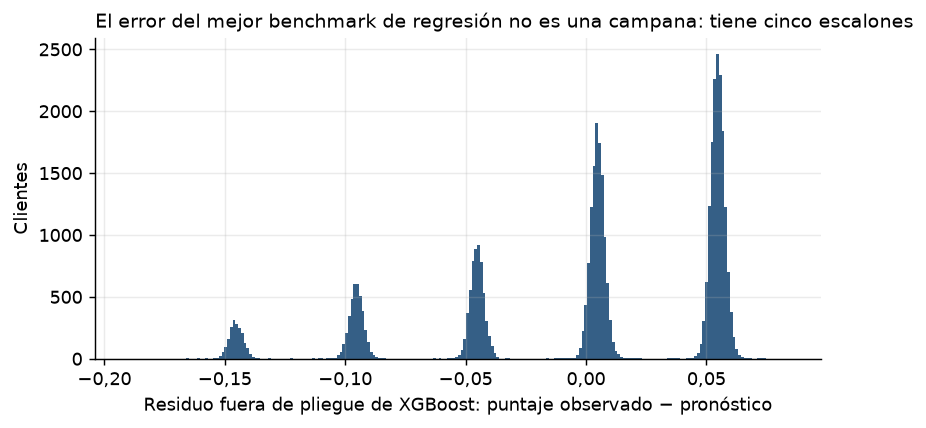

In [2]:
# Figura 5.1. Histograma de los residuos fuera de pliegue de XGBoost sobre las
# 38.978 filas de entrenamiento
# (Entrega3/resultados/complementos/fuera_de_pliegue.parquet): cada fila se predice
# con un modelo que no la vio.
inf.figura('residuos_escalones')

Todos los benchmarks tratan ese escalón como ruido:

- los **regresores** minimizan el error cuadrático, que es la pérdida correcta cuando el ruido es normal. Con ruido
  multimodal siguen siendo consistentes, pero **ineficientes**: usan los datos como si la varianza del error fuera la
  del escalón (desviación 0,059), cuando dentro de cada escalón el error es unas ochenta veces menor (Proposición 4);
- los **clasificadores** solo ven la etiqueta «riesgo alto» (`s > τ`) y desechan el puntaje continuo que la define, es
  decir, cuánto le falta o le sobra a cada cliente para llegar al umbral. Dicotomizar una respuesta continua descarta
  información {cite}`cohen1983,royston2006`.

La ineficiencia de los regresores se puede medir con el error del índice, la parte del pronóstico que depende de los
predictores. La medida se hizo con los modelos finales y se adelanta aquí porque es la que mejor describe la limitación.

In [3]:
# Error del índice del mejor benchmark de regresión y del modelo original en la
# partición de prueba: lee resultados/predicciones_prueba.parquet y reconstruye el
# índice real con active_products, que ningún modelo recibe.
inf.texto('error_indice')

**Evidencia en la partición de prueba.** El pronóstico de un regresor de mínimos cuadrados es el índice más el desplazamiento medio; restándole ese desplazamiento queda el índice que el modelo aprendió. El de XGBoost se aparta del índice real con una desviación de 0,00316; el del modelo original, que separa el escalón, con una de 0,00130 (2,4 veces menor). El índice real se reconstruye con `active_products`, que ningún modelo recibe: se usa solo para esta medida.


El diseño responde directamente a esa limitación: **modelar el escalón como una clase latente y quitárselo al objetivo
antes de cada paso de boosting**.

## 5.2. Formulación

Para un cliente con predictores $x$ y puntaje $s$:

$$
s = F(x) + c_{z} + e, \qquad z \in \{1,\dots,K\},\quad P(z = k) = \pi_k,\quad e \sim \mathcal N(0, \sigma^2),
$$ (eq-modelo)

con $z$ independiente de $x$ y de $e$. $F(x) = \beta_0 + \nu\sum_{t=1}^{T} h_t(x)$ es una suma de árboles de regresión
de profundidad $d$ sobre las variables discretizadas en intervalos (*bins*); con $d = 1$ es un modelo aditivo, $F(x) = \beta_0 + \sum_j f_j(x_j)$,
con una curva por variable. $z$ es la **clase latente** (no se observa), $c_k$ el **desplazamiento** de la clase $k$,
$\pi_k$ su peso y $\sigma$ la dispersión dentro de cada clase. Con $K = 1$ el modelo es el boosting de mínimos
cuadrados de {cite:t}`friedman2001`.

Los parámetros son $F$ y $\theta = (\pi, c, \sigma)$. La log-verosimilitud observada de $n$ clientes es

$$
\ell(F, \theta) = \sum_{i=1}^{n} \log \sum_{k=1}^{K} \pi_k\, \varphi_\sigma\!\big(s_i - F(x_i) - c_k\big),
$$ (eq-vero)

donde $\varphi_\sigma$ es la densidad normal de media 0 y desviación $\sigma$. Maximizarla directamente es difícil por
la suma dentro del logaritmo; el algoritmo EM {cite}`dempster1977` la sustituye por una cota que sí se puede maximizar.

**Supuestos.** (S1) El desplazamiento es aditivo y no depende de $x$. (S2) La clase latente es independiente de los
predictores. (S3) El error dentro de cada clase tiene la misma dispersión. En COFINFAD los tres se cumplen: el salto
medio entre niveles de `active_products` es constante (0,050), la variable no se puede predecir con las demás (AUC de
0,50 al intentarlo) y la dispersión del puntaje dentro de cada nivel es la misma (0,032 en los cinco). Cuando no se cumplen, el modelo no deja
de funcionar: el criterio BIC elige $K = 1$ y BDL se reduce a un boosting de mínimos cuadrados (sección 5.6).

## 5.3. La regla de aprendizaje: EM generalizado con paso de boosting

Sea $r_i = s_i - F(x_i)$ el residuo. Cada vuelta hace tres cosas.

**Paso E.** Con el índice y la mezcla actuales, la probabilidad de que el cliente $i$ pertenezca a la clase $k$ es

$$
\gamma_{ik} = \frac{\pi_k\, \varphi_\sigma(r_i - c_k)}{\sum_{l} \pi_l\, \varphi_\sigma(r_i - c_l)}.
$$ (eq-e)

**Pasos de boosting (paso M parcial sobre $F$).** La esperanza de la log-verosimilitud completa es

$$
Q(F,\theta) = \sum_i\sum_k \gamma_{ik}\Big[\log\pi_k - \log\sigma - \tfrac{1}{2\sigma^2}\big(s_i - c_k - F(x_i)\big)^2\Big] + \text{cte}.
$$ (eq-q)

Como $\sum_k \gamma_{ik} = 1$, el término cuadrático se separa en dos:
$\sum_k \gamma_{ik}(s_i - c_k - F_i)^2 = (\tilde s_i - F_i)^2 + \operatorname{Var}_{\gamma_i}(c)$, con

$$
\tilde s_i = s_i - \sum_k \gamma_{ik}\, c_k
$$ (eq-sin-escalon)

el **objetivo sin escalón**: el puntaje menos el desplazamiento esperado de su clase. La varianza no depende de $F$,
así que maximizar $Q$ en $F$ es minimizar $\sum_i (\tilde s_i - F(x_i))^2$. No se resuelve del todo: se dan $B$ pasos de
boosting. En cada uno se ajusta un árbol $h$ al residuo $\tilde s_i - F(x_i)$ y se actualiza $F \leftarrow F + \nu h$.
El árbol se construye por niveles: en cada nodo elige la variable $j$ y el corte $b$ que maximizan la ganancia

$$
\frac{G_L^2}{N_L + \lambda} + \frac{G_R^2}{N_R + \lambda} - \frac{G^2}{N + \lambda},
$$ (eq-ganancia)

donde $G$ y $N$ son la suma de residuos y el número de filas del nodo, y $L$ y $R$ sus dos hijos; el valor de una hoja
es $v = G/(N + \lambda)$.

**Paso M (sobre $\theta$).** Con el índice ya actualizado, $r_i = s_i - F(x_i)$:

$$
\pi_k = \frac1n\sum_i \gamma_{ik},\qquad c_k = \frac{\sum_i \gamma_{ik}\, r_i}{\sum_i \gamma_{ik}},\qquad
\sigma^2 = \frac1n\sum_i\sum_k \gamma_{ik}\,(r_i - c_k)^2 .
$$ (eq-m)

```{admonition} Algoritmo 1. Ajuste de BDL
:class: note

**Entradas:** datos $(x_i, s_i)_{i=1}^n$; tasa $\nu \in (0,1]$; profundidad $d$; bins $M$; mínimo de hoja; $\lambda \ge 0$;
vueltas máximas $V$; árboles por vuelta $B$; árboles de calentamiento $T_0$; $K_{\max}$; paciencia $P$.
**Salidas:** $F$, $(\pi, c, \sigma)$, residuos de calibración.

1. **Reparto.** Dividir las filas al azar en ajuste (80 %), validación (10 %) y calibración (10 %).
2. **Discretización.** Con las filas de ajuste, cortar cada variable en a lo sumo $M$ bins (un bin por valor si hay
   pocos valores distintos; cuantiles si hay muchos).
3. **Calentamiento ($K = 1$).** $F \leftarrow \bar s$. Repetir hasta $T_0$ veces: ajustar un árbol a $s_i - F(x_i)$ y
   sumar $\nu h$ a $F$. Cortar antes si el error de validación no baja en 10 árboles, y volver al mejor.
4. **Mezcla inicial.** Con el residuo $r_i$ de las filas de ajuste: para $K = 1,\dots,K_{\max}$, K-medias exacto en una
   dimensión sobre el histograma de $r$ y EM de la mezcla; elegir el $K$ de menor BIC y conservar solo los
   desplazamientos separados por al menos $4\sigma$ y con al menos el 1 % de las filas.
5. **EM generalizado.** Para $v = 1,\dots,V$:
   1. *Paso E:* $\gamma_{ik}$ con {eq}`eq-e`; objetivo sin escalón $\tilde s_i$ con {eq}`eq-sin-escalon`.
   2. *Boosting:* $B$ veces, ajustar un árbol a $\tilde s_i - F(x_i)$ y sumar $\nu h$ a $F$.
   3. *Paso M:* $\pi$, $c$, $\sigma$ con {eq}`eq-m`.
   4. *Parada:* medir en validación el error dentro de clase, $\big(\tfrac1m\sum_i \min_k (r_i - c_k)^2\big)^{1/2}$; si no
      mejora en $P$ vueltas, detenerse.
6. **Selección.** Quedarse con los árboles y la mezcla de la mejor vuelta en validación.
7. **Calibración.** Guardar los residuos $r_j = s_j - F(x_j)$ de las filas de calibración.

**Criterio de parada:** $P$ vueltas sin mejora en validación, o $V$ vueltas.
```

**Valores usados.** En todos los experimentos $V = 400$, $B = 5$, $T_0 = 100$, $K_{\max} = 8$ y $P = 20$, que son los
valores por defecto de la clase; no se buscan. La búsqueda de hiperparámetros ({ref}`Tabla 3.2 <tab-espacios>`) mueve
la tasa $\nu$, la profundidad $d$, el mínimo de hoja, $\lambda$, el número de bins $M$ y si se usa la mezcla
(`n_componentes`: «auto», que deja la elección de $K$ al BIC, o 1); en clasificación, además, si se aprende del puntaje
o de la etiqueta (`usar_puntaje`).

## 5.4. La regla de salida

**Regresión.** La media predicha es $\hat s(x) = F(x) + \sum_k \pi_k c_k$. La distribución predictiva de un cliente
nuevo es $F(x) + r_j$, con $r_j$ los residuos de calibración, en la línea de las distribuciones predictivas conformes
{cite}`vovk2019`; de ella salen la mediana, los cuantiles y los intervalos.
El **conjunto de predicción** de cobertura $1-\alpha$ usa la densidad de la mezcla, $f(r) = \sum_k \pi_k \varphi_{\sigma}(r - c_k)$,
como medida de conformidad:

$$
C_\alpha(x) = \{\, s : f(s - F(x)) \ge t_\alpha \,\},
$$ (eq-conjunto)

con $t_\alpha$ el $\lfloor \alpha(m+1) \rfloor$-ésimo menor valor de $f(r_j)$ entre los $m$ residuos de calibración. Con
escalones, $C_\alpha(x)$ es una unión de intervalos cortos, uno alrededor de cada nivel.

**Clasificación.** La etiqueta es $y = \mathbb 1[s > \tau]$. La probabilidad de la clase positiva sale del modelo:

$$
P(s > \tau \mid x) = \sum_{k=1}^{K} \pi_k\, \Phi\!\left(\frac{F(x) + c_k - \tau}{\sigma_r}\right),
$$ (eq-excedencia)

donde $\sigma_r$ es la dispersión robusta del error dentro de clase medida en validación (1,4826 veces la mediana de
las desviaciones absolutas). Cada clase latente aporta su peso si su nivel $F(x) + c_k$ queda por encima del umbral.
El umbral $\tau$ no se pasa como hiperparámetro: se deduce de los datos, como el punto medio entre el mayor puntaje de
un negativo y el menor de un positivo.

Si `fit` no recibe el puntaje (o `usar_puntaje = False`), el clasificador aprende de la etiqueta con el mismo motor
de árboles y pérdida logística (modo directo, Proposición 2). Es la variante «sin puntaje» de la ablación.

## 5.5. Sustento teórico

Las demostraciones usan solo álgebra y resultados clásicos; cada proposición tiene una prueba unitaria que la verifica
numéricamente.

```{admonition} Proposición 1. La verosimilitud no decrece
:class: important

Sea $(F, \theta)$ el estado al empezar una vuelta del Algoritmo 1 y $(F', \theta')$ el estado al terminarla, con
$\nu \in (0, 2)$ y $\lambda \ge 0$. Entonces $\ell(F', \theta') \ge \ell(F, \theta)$. Además, si $\sigma \ge \sigma_{\min} > 0$,
la sucesión de verosimilitudes está acotada y converge.
```

**Demostración.** Por la descomposición de EM {cite}`dempster1977`, para cualquier $(F', \theta')$,
$\ell(F',\theta') - \ell(F,\theta) \ge Q(F',\theta') - Q(F,\theta)$, donde $Q$ se calcula con las $\gamma_{ik}$ del
paso E en $(F,\theta)$ (la diferencia es una divergencia de Kullback-Leibler, que no es negativa). Basta ver que ninguno
de los pasos baja $Q$.

*Boosting.* Con $\theta$ fijo, $Q$ depende de $F$ solo a través de $-\frac{1}{2\sigma^2}\sum_i(\tilde s_i - F_i)^2$. Un
árbol parte las filas en hojas $R_1,\dots,R_L$; sean $S_l = \sum_{i\in R_l}(\tilde s_i - F_i)$ y $n_l$ el tamaño de la
hoja, con valor $v_l = S_l/(n_l+\lambda)$. Tras $F' = F + \nu h$, el cambio de la suma de cuadrados es

$$
\sum_l \big(-2\nu v_l S_l + \nu^2 v_l^2 n_l\big)
= \sum_l \frac{S_l^2}{n_l+\lambda}\Big(-2\nu + \nu^2\frac{n_l}{n_l+\lambda}\Big)
\le -\nu(2-\nu)\sum_l \frac{S_l^2}{n_l+\lambda} \le 0 .
$$ (eq-descenso)

*Paso M.* Con $F'$ y $\gamma$ fijos, {eq}`eq-m` es el máximo de $Q$ en $\pi$ (multiplicador de Lagrange), en $c$ (media
ponderada) y en $\sigma$; con el piso $\sigma_{\min}$, el máximo restringido es $\max(\sigma^*, \sigma_{\min})$ porque $Q$
es unimodal en $\sigma$. Por tanto $Q(F',\theta') \ge Q(F',\theta) \ge Q(F,\theta)$.

*Cota.* Cada sumando de {eq}`eq-vero` es a lo sumo $\log\big(1/(\sigma_{\min}\sqrt{2\pi})\big)$: una sucesión monótona y
acotada converge. ∎

El calentamiento es el caso $K = 1$, así que la proposición lo cubre. Verificación: `test_verosimilitud_no_decrece` y
`test_verosimilitud_no_decrece_con_arboles_profundos`.

```{admonition} Proposición 2. En modo directo, la pérdida logística no sube
:class: important

Sea $L(F) = \sum_i \big[\log(1 + e^{F_i}) - y_i F_i\big]$ y $p_i = 1/(1+e^{-F_i})$. Si cada hoja da el paso
$v_l = G_l/(n_l/4 + \lambda)$, con $G_l = \sum_{i \in R_l}(y_i - p_i)$, y $\nu \in (0,2)$, entonces $L(F + \nu h) \le L(F)$.
```

**Demostración.** La segunda derivada de $\log(1+e^{f}) - yf$ es $p(1-p) \le 1/4$, de modo que
$L(F+\delta) \le L(F) - \sum_i \delta_i (y_i - p_i) + \tfrac18\sum_i \delta_i^2$ {cite}`bohning1988`. Con
$\delta_i = \nu v_l$ en la hoja $l$,

$$
L(F+\nu h) - L(F) \le \sum_l \frac{G_l^2}{n_l/4+\lambda}\Big(-\nu + \frac{\nu^2}{2}\cdot\frac{n_l/4}{n_l/4+\lambda}\Big)
\le -\nu\big(1 - \tfrac{\nu}{2}\big)\sum_l \frac{G_l^2}{n_l/4+\lambda} \le 0 .
$$ (eq-descenso-logistico)

∎

Verificación: `test_perdida_logistica_no_sube`.

```{admonition} Proposición 3. Cobertura de los conjuntos de predicción
:class: important

Si las filas de calibración y el cliente nuevo son intercambiables, el conjunto {eq}`eq-conjunto` cumple
$P\big(s \in C_\alpha(x)\big) \ge 1 - \alpha$, sin suponer que el modelo {eq}`eq-modelo` sea correcto.
```

**Demostración.** $F$ y $f$ se calculan con las filas de ajuste y de validación, de modo que son fijas respecto de las de calibración. Los
valores $a_j = f(r_j)$ de las $m$ filas de calibración y el del cliente nuevo, $a = f(s - F(x))$, son entonces
intercambiables, y el rango de $a$ entre los $m+1$ es uniforme. El cliente queda fuera del conjunto solo si $a$ es
menor que $t_\alpha$, es decir, si está entre los $\lfloor\alpha(m+1)\rfloor$ menores, lo que ocurre con probabilidad
a lo sumo $\alpha$ {cite}`vovk2005,lei2018`. ∎

Verificación: `test_cobertura_conforme`.

```{admonition} Proposición 4. El error cuadrático desperdicia información cuando hay escalones
:class: important

Sea $r = c_z + e$ el error del modelo {eq}`eq-modelo`, con densidad $f$, e $I_f = \int (f')^2/f$ su información de
Fisher para un parámetro de localización. Entonces

$$
\frac{1}{\sigma^2 + \operatorname{Var}(c_z)} \;\le\; I_f \;\le\; \frac{1}{\sigma^2},
$$ (eq-fisher)

con igualdad a la izquierda solo si $K = 1$, e $I_f \to 1/\sigma^2$ cuando la separación entre desplazamientos crece
frente a $\sigma$.
```

**Demostración.** *Izquierda.* La media muestral es un estimador insesgado de la localización con varianza
$(\sigma^2 + \operatorname{Var}(c_z))/n$; por la cota de Cramér-Rao esa varianza es al menos $1/(n I_f)$. La igualdad
exige que la derivada de $\log f$ sea lineal, es decir, que $f$ sea normal. *Derecha.* Si además se observara $z$, la
información sería $1/\sigma^2$; observar menos no puede dar más (principio de la información faltante
{cite}`dempster1977`). *Límite.* Con las clases separadas, $\gamma_{ik}$ tiende a 0 o a 1 y la información faltante
tiende a cero. ∎

Verificación: `test_informacion_de_fisher_entre_las_cotas`, que integra numéricamente $I_f$ para mezclas con distinta
separación.

Consecuencia: el estimador de mínimos cuadrados tiene varianza proporcional a $\sigma^2 + \operatorname{Var}(c_z)$ y
el de máxima verosimilitud de la mezcla, a $1/I_f$. En COFINFAD, $\operatorname{Var}(c_z) = 0{,}059^2$ y
$\sigma \approx 0{,}0007$: la cota {eq}`eq-fisher` dice que la estructura de los datos permitiría una varianza varios
miles de veces menor que la de los mínimos cuadrados. En la práctica la ganancia es mucho más modesta (el error del
índice se reduce a menos de la mitad, sección 5.1), porque lo que queda ya no es varianza sino error de aproximación:
los bins, la cola de `tx_count` y el número finito de árboles. Y por eso BDL afina el índice aunque el RMSE apenas se
mueva: el RMSE está dominado por el escalón, que ningún modelo puede predecir.

```{admonition} Proposición 5. La probabilidad de excedencia es la regla de Bayes del modelo
:class: important

Si {eq}`eq-modelo` se cumple, $P(s > \tau \mid x) = \sum_k \pi_k \Phi\big((F(x) + c_k - \tau)/\sigma\big)$. Cuando
$\sigma \to 0$ es una función escalonada de $F(x)$ que solo toma los valores $\sum_{k:\,F(x)+c_k>\tau}\pi_k$.
```

**Demostración.** Condicionando en la clase, $P(s>\tau\mid x, z=k) = P(e > \tau - F(x) - c_k) = \Phi\big((F(x)+c_k-\tau)/\sigma\big)$, y se
promedia con $\pi_k$ porque $z$ es independiente de $x$. ∎

La regla implementada, {eq}`eq-excedencia`, es esa misma expresión con los parámetros estimados y con una sola
sustitución: en lugar de la $\sigma$ del paso M usa la dispersión robusta $\sigma_r$ medida en validación. Es, por
tanto, un estimador de la regla de Bayes y no la regla exacta: coincide con ella cuando el modelo se cumple y $\sigma_r$
estima $\sigma$, y la razón de preferir $\sigma_r$ está en la {ref}`Tabla 5.2 <tab-decisiones>`. Verificación:
`test_excedencia_coincide_con_la_frecuencia`, que compara la probabilidad con la frecuencia observada en datos nuevos.

La consecuencia práctica es un **techo**: dentro de una meseta todos los clientes tienen la misma probabilidad, y
ningún clasificador puede ordenarlos mejor que al azar. El techo del AUC se calcula con $\pi$ y la distribución de
$F(x)$; en COFINFAD vale 0,835 en entrenamiento y 0,831 en prueba (sección 6.4).

**Convergencia observada.** La {ref}`Figura 5.2 <fig-convergencia>` muestra el ajuste del modelo final de regresión
sobre COFINFAD, y la {ref}`Tabla 5.1 <tab-bic>`, cómo elige el número de clases.

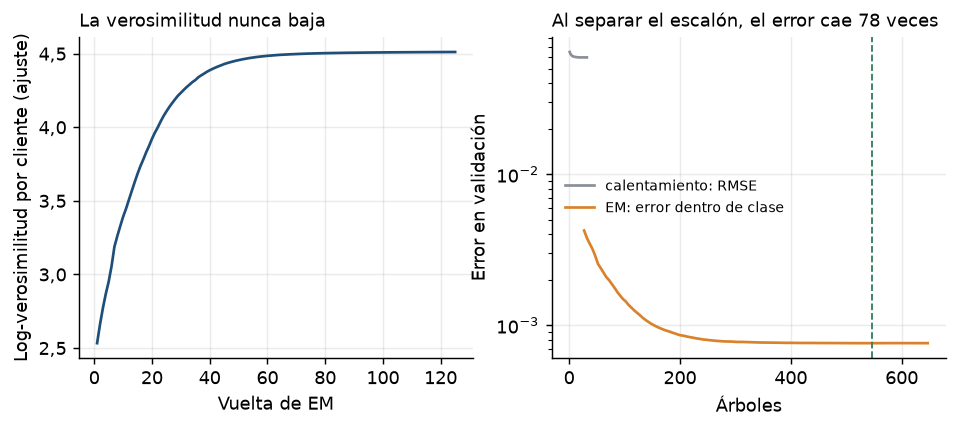

In [4]:
# Figura 5.2. Carga la tubería final de regresión (resultados/modelos) y dibuja su
# atributo historial_: la verosimilitud de cada vuelta de EM y el error de
# validación del calentamiento y del EM.
inf.figura('convergencia')

(tab-bic)=
**Tabla 5.1.** Elección del número de clases latentes en el modelo final de regresión: criterio BIC de la mezcla
ajustada al residuo del calentamiento para cada $K$, y clases que quedan tras la regla de parsimonia.

In [5]:
# Tabla 5.1. Del mismo historial_: el BIC de cada K y las clases útiles (separadas
# 4σ y con al menos el 1 % de las filas).
inf.tabla('tabla_bic')

| K | BIC | Clases que quedan tras la regla de parsimonia |
| ---: | ---: | ---: |
| 1 | −88.023 | 1 |
| 2 | −95.867 | 1 |
| 3 | −98.143 | 2 |
| 4 | −116.023 | 4 |
| 5 | −157.752 | 5 |
| 6 | −157.731 | 5 |
| 7 | −157.712 | 5 |
| 8 | −157.692 | 5 |

Modelo final de regresión: K = 5; pesos 0,050, 0,098, 0,149, 0,301, 0,402; separación media entre desplazamientos 0,0500; 547 árboles (22 de calentamiento); dispersión dentro de clase en validación 0,00076 (robusta: 0,00005).


El BIC deja de mejorar al pasar de cinco clases, y la regla de parsimonia descarta las que solo parten un escalón en
dos: el modelo encuentra los cinco niveles sin que nadie le diga cuántos hay.

## 5.6. Decisiones de diseño y su justificación

(tab-decisiones)=
**Tabla 5.2.** Decisiones de diseño del algoritmo y su justificación.

| Decisión | Justificación |
|---|---|
| Un solo índice $F$ y desplazamientos constantes (no una regresión por clase) | Es lo que dice la evidencia: el salto entre niveles es constante. Con $K$ regresiones habría $K$ veces más parámetros y cada una vería menos datos |
| Calentamiento con $K = 1$ y parada temprana | Los escalones solo se distinguen cuando el residuo es menor que su separación; cortar a tiempo evita que el sobreajuste los deforme |
| K-medias exacto sobre el histograma para iniciar la mezcla | Determinista, de costo independiente de $n$, y no deja dos centros en el mismo escalón |
| $K$ por BIC con regla de parsimonia | El BIC premia partir un escalón en dos componentes superpuestos o dedicar uno a un puñado de atípicos; ninguno es una clase latente |
| Varios árboles por vuelta de EM | Las responsabilidades cambian despacio; recalcularlas tras cada árbol cuesta más que el árbol |
| Paso de hoja por cota cuadrática en modo directo | Garantiza el descenso de la pérdida (Proposición 2) sin búsqueda en línea |
| Dispersión robusta en la excedencia | El índice se equivoca mucho en menos del 1 % de los clientes; con la raíz del error cuadrático medio esos pocos ensanchan la transición de todos |
| Reparto interno 80/10/10 | Separa los tres usos de los datos: ajustar los árboles, decidir cuándo parar y calibrar la salida conforme |

## 5.7. Complejidad

Sean $n$ filas, $p$ columnas, $M$ bins por columna, $T$ árboles de profundidad $d$, $V$ vueltas de EM y $K$ clases.

- **Discretización:** $O(n\,p \log n)$, una vez.
- **Un árbol:** el histograma de la raíz es un producto de la matriz indicadora (un uno por fila y columna) por el
  vector de residuos, $O(n\,p)$. En cada nivel siguiente solo se calcula el histograma del hijo con menos filas y el
  otro sale por resta, a lo sumo $O(n\,p/2)$ por nivel. Elegir los cortes cuesta $O(2^d\, p\, M)$.
- **Pasos E y M:** $O(n\,K)$ por vuelta.

En total, el entrenamiento es $O\big(T\,(n\,p\,d + 2^d p M) + V n K\big)$ en tiempo y $O(n\,p)$ en memoria. La
inferencia es $O(p \log M)$ por cliente con $d = 1$ (una búsqueda de bin y una consulta por variable, sin recorrer
árboles) y $O(T\,d)$ con árboles más profundos. El contraste con los tiempos medidos al variar $n$ y $p$ está en el
capítulo 7.

## 5.8. Implementación y pruebas unitarias

La clase `RegresorBDL` hereda de `RegressorMixin` y `BaseEstimator`; `ClasificadorBDL`, de `ClassifierMixin` y
`BaseEstimator`, con `fit`, `predict` y `predict_proba`. `ModeloOriginal` es un alias de `ClasificadorBDL`. El puntaje
continuo entra por `fit(X, y, puntaje=s)`, como cualquier parámetro de ajuste de scikit-learn: la validación cruzada lo
recorta a las filas de entrenamiento de cada pliegue. La {ref}`Tabla 5.3 <tab-piezas>` dice en qué función está cada
pieza del algoritmo y la {ref}`Tabla 5.4 <tab-pruebas-unitarias>`, qué prueba cubre cada requisito de la guía.

(tab-piezas)=
**Tabla 5.3.** Piezas del algoritmo y función que las implementa.

| Pieza | Función en `original_model.py` |
|---|---|
| Discretización | `calcular_cortes`, `codificar` |
| Histogramas por bin | `_Histogramas` (matriz indicadora dispersa) |
| Árbol de regresión propio | `_mejor_corte`, `ajustar_arbol`, `predecir_arbol` |
| Mezcla | `paso_e`, `paso_m`, `_kmedias_1d`, `ajustar_mezcla`, `elegir_componentes` |
| EM generalizado | `RegresorBDL.fit` |
| Salida | `prob_excedencia`, `cuantil`, `intervalo`, `conjunto_residual`, `conjunto_cubre` |
| Interpretación | `contribuciones` (valores de Shapley exactos), `importancia`, `formas_` |
| Modo directo | `ClasificadorBDL._ajustar_directo` |

Las pruebas (`python -m pytest -q` en `ModeloOriginal/`; se ejecutan en cada *push* con GitHub Actions) cubren lo que
pide la guía:

(tab-pruebas-unitarias)=
**Tabla 5.4.** Requisitos de la guía para las pruebas unitarias y prueba que cubre cada uno.

| Requisito de la guía | Prueba |
|---|---|
| Aprende en datos sintéticos con solución conocida | `test_recupera_los_escalones`, `test_la_mezcla_mejora_al_boosting_de_minimos_cuadrados`, `test_ruido_unimodal_deja_un_solo_componente`, `test_aprende_mejor_que_azar` |
| Reproducibilidad con la misma semilla | `test_reproducible_con_misma_semilla` |
| Entradas inválidas | `test_entrada_invalida`, `test_etiqueta_que_no_es_un_umbral` |
| Compatibilidad con `clone` y `Pipeline` | `test_clone_conserva_hiperparametros`, `test_entra_en_pipeline_y_validacion_cruzada` |
| Propiedades teóricas | `test_verosimilitud_no_decrece`, `test_perdida_logistica_no_sube`, `test_cobertura_conforme`, `test_informacion_de_fisher_entre_las_cotas`, `test_excedencia_coincide_con_la_frecuencia`, `test_aportes_suman_la_prediccion` |
| Piezas internas | `test_arbol_propio`, `test_histograma_por_filas_coincide_con_el_total`, `test_kmedias_1d_es_exacto`, `test_pasos_e_y_m` |
| El módulo no importa ningún modelo | `test_el_modelo_original_no_importa_ningun_modelo` |

## 5.9. Ablación

Cada variante retira un componente y pasa por el mismo procedimiento que el modelo completo (validación anidada de
5 × 3, semilla 42, 30 evaluaciones). Se compara con el modelo completo con dos de las pruebas del protocolo: la *t*
corregida sobre los pliegues externos (P2) y la prueba pareada sobre la partición de prueba (P3: permutación en
regresión y DeLong en clasificación), con el ajuste de Holm entre las variantes de cada tarea. La
{ref}`Tabla 5.5 <tab-ablacion>` dice cuánto aporta cada componente.

(tab-ablacion)=
**Tabla 5.5.** Ablación: métrica de cada variante en los pliegues externos y en prueba, y aporte del componente
retirado (lo que mejora el modelo completo respecto de la variante), con su p-valor ajustado por Holm.

In [6]:
# Tabla 5.5. Lee resultados/ablacion.csv, que escribe experiments/07_ablacion.py:
# cada variante pasa por la misma validación anidada que el modelo completo y se
# compara con él con la t corregida (pliegues) y en prueba.
inf.tabla('tabla_ablacion')

**Regresión (RMSE, menor es mejor).**

| Variante | RMSE externo | RMSE en prueba | Aporte del componente (externo) | p (*t* corregida, Holm) | Aporte en prueba | p (prueba, Holm) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **BDL completo** | 0,05887 ± 0,00041 | 0,05912 | — | — | — | — |
| BDL sin mezcla (K = 1) | 0,05898 ± 0,00041 | 0,05910 | 0,000107 (5/5) | 0,040 | −0,000016 | 0,625 |

**Clasificación (AUC, mayor es mejor).**

| Variante | AUC externo | AUC en prueba | Aporte del componente (externo) | p (*t* corregida, Holm) | Aporte en prueba | p (prueba, Holm) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **BDL completo** | 0,8320 ± 0,0026 | 0,8311 | — | — | — | — |
| BDL sin mezcla (K = 1) | 0,8299 ± 0,0009 | 0,8311 | 0,00211 (5/5) | 0,652 | −0,00009 | 1,000 |
| BDL sin puntaje (aprende de la etiqueta) | 0,8292 ± 0,0028 | 0,8253 | 0,00284 (4/5) | 0,652 | 0,00578 | 0,065 |
| BDL con salida conforme empírica | 0,8313 ± 0,0024 | 0,8315 | 0,00075 (3/5) | 0,729 | −0,00044 | 1,000 |

Aporte: lo que mejora el modelo completo respecto de la variante (positivo: el componente ayuda). En prueba, la comparación es DeLong en clasificación y permutación pareada en regresión.

**Lectura.** En regresión (RMSE), retirar la mezcla ($K = 1$) cuesta 0,000107 en la media externa (el modelo completo va por delante en 5 de 5 pliegues; p = 0,040) y en prueba la variante queda 0,000016 por delante (p = 0,625). En clasificación (AUC), retirar la mezcla ($K = 1$) cuesta 0,00211 en la media externa (el modelo completo va por delante en 5 de 5 pliegues; p = 0,652) y en prueba la variante queda 0,00009 por delante (p = 1,000); aprender de la etiqueta en lugar del puntaje cuesta 0,00284 en la media externa (el modelo completo va por delante en 4 de 5 pliegues; p = 0,652) y en prueba cuesta 0,00578 (p = 0,065); cambiar la salida de la mezcla por la conforme empírica cuesta 0,00075 en la media externa (el modelo completo va por delante en 3 de 5 pliegues; p = 0,729) y en prueba la variante queda 0,00044 por delante (p = 1,000). Tras el ajuste de Holm, en los pliegues externos solo es significativo el costo de retirar la mezcla ($K = 1$) en regresión; en prueba, ninguno. En clasificación, lo que más pesa en prueba es aprender del puntaje continuo y no de su dicotomización: es la diferencia entre un AUC de 0,8311 y uno de 0,8253. Que los aportes sean tan pequeños es coherente con la sección 6.4: con todas las filas, un boosting sin mezcla ya está casi en el límite del conjunto. En regresión la mezcla no cambia lo que el modelo estima, que es la media condicional del puntaje, sino con cuántos datos lo consigue (sección 7.5). Lo que añade es lo que el modelo sabe del error: cuántos niveles hay, dónde están y con qué probabilidad (sección 7.8).


## 5.10. Interpretabilidad

Con profundidad 1 el índice es aditivo y cada variable aporta una curva que se puede graficar, igual que en la EBM.
El aporte de una variable a la predicción de un cliente es el valor de su curva menos la media de esa curva: son los
valores de Shapley {cite}`lundberg2017` exactos de un modelo aditivo. Con árboles más profundos, `contribuciones` reparte cada árbol
enumerando los subconjuntos de sus variables, de modo que la suma de los aportes es exactamente la predicción
(`test_aportes_suman_la_prediccion`). La {ref}`Tabla 5.6 <tab-importancia>` ordena las variables por su aporte y la
{ref}`Figura 5.3 <fig-formas>` muestra las curvas de las tres primeras.

(tab-importancia)=
**Tabla 5.6.** Importancia global en el modelo final de regresión: aporte medio absoluto de cada variable al puntaje
predicho (valores de Shapley exactos, 2.000 clientes de prueba) y comparación con el mejor benchmark.

In [7]:
# Tabla 5.6. Carga la tubería final de regresión, calcula contribuciones() sobre
# 2.000 clientes de prueba y promedia su valor absoluto por variable; la comparación
# usa los valores SHAP de XGBoost que publica el dashboard.
inf.tabla('tabla_importancia')

| N.º | Variable | Aporte medio absoluto al puntaje | Parte del total |
| ---: | :--- | ---: | ---: |
| 1 | `age` | 0,02084 | 45,5 % |
| 2 | `app_logins_frequency` | 0,01512 | 33,0 % |
| 3 | `satisfaction_score` | 0,00956 | 20,9 % |
| 4 | `tx_count` | 0,00017 | 0,4 % |
| 5 | `n_tx` | 0,00003 | 0,1 % |
| 6 | `base_satisfaction` | 0,00002 | 0,1 % |
| 7 | `total_tx_volume` | 0,00001 | 0,0 % |
| 8 | `prop_Withdrawal` | 0,00001 | 0,0 % |

Las cinco variables de más peso en BDL son `age`, `app_logins_frequency`, `satisfaction_score`, `tx_count`, `n_tx`; en el mejor benchmark de regresión (XGBoost, valores SHAP de 500 clientes de prueba), `age`, `app_logins_frequency`, `satisfaction_score`, `base_satisfaction`, `monto_mediano`.


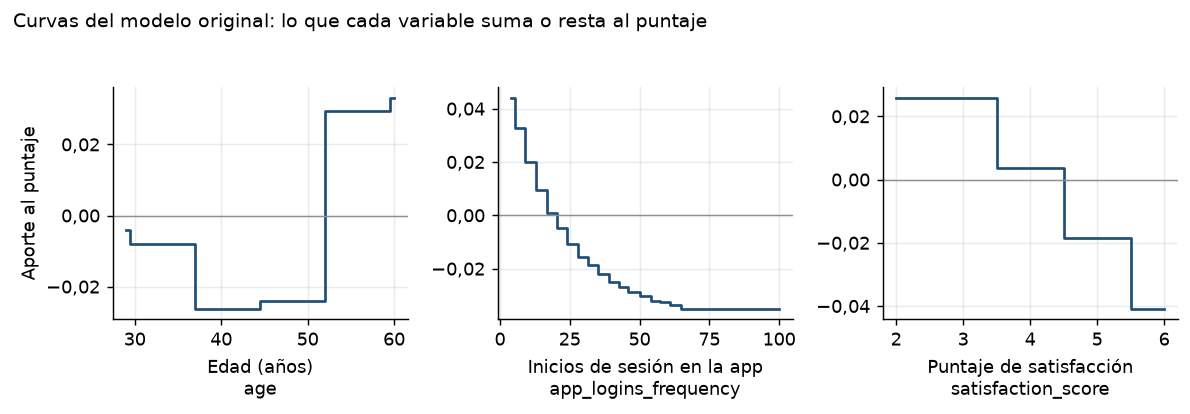

In [8]:
# Figura 5.3. Dibuja el atributo formas_ del modelo (una curva por variable,
# definida en cada bin), centrado en su media y devuelto a la escala original de la
# variable con la media y la desviación del preprocesamiento.
inf.figura('formas_bdl')